In [2]:
from torchaudio.transforms import MelSpectrogram

import datasets
import matplotlib.pyplot as plt
import torch
import soundfile as sf

/home/xkukht01/Dev/SFC/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# experiments setup
_SAVE_SAMPLE_TO_FILE = True

SAMPLE_FILE = ".data/sample.wav"

DATASET_PATH = "openslr/librispeech_asr"
DATASET_NAME = "clean"
DATASET_SPLIT = "train.100"

SR = 16000
N_FFT = 400
HOP_LENGTH = 160
N_MELS = 80

In [4]:
dataset = datasets.load_dataset(DATASET_PATH, DATASET_NAME, split=DATASET_SPLIT, streaming=True)
sample = next(iter(dataset))

In [5]:
print(sample.keys(), end="\n\n")

audio, text = sample['audio'], sample['text']
print(f"Audio: {audio.keys()}, {audio}")
print(f"Text: {text}")

audio_tensor = torch.as_tensor(audio['array'], dtype=torch.float32)

if _SAVE_SAMPLE_TO_FILE:
    sf.write(SAMPLE_FILE, audio["array"], audio["sampling_rate"])

dict_keys(['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id'])

Audio: dict_keys(['path', 'array', 'sampling_rate']), {'path': '374-180298-0000.flac', 'array': array([ 7.01904297e-04,  7.32421875e-04,  7.32421875e-04, ...,
       -2.74658203e-04, -1.83105469e-04, -3.05175781e-05], shape=(232480,)), 'sampling_rate': 16000}
Text: CHAPTER SIXTEEN I MIGHT HAVE TOLD YOU OF THE BEGINNING OF THIS LIAISON IN A FEW LINES BUT I WANTED YOU TO SEE EVERY STEP BY WHICH WE CAME I TO AGREE TO WHATEVER MARGUERITE WISHED


In [ ]:
mel_transformer = MelSpectrogram(
    sample_rate=SR,
    n_fft=N_FFT,
    win_length=N_FFT,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    power=2.0
)

audio_mel_spectr = mel_transformer(audio_tensor)
audio_log_mel = torch.log(audio_mel_spectr.clamp_min(1e-6))

print(f"Shape of mel spectr: {audio_mel_spectr.shape}")
print(f"Shape of log-mel spectr: {audio_log_mel.shape}")

Shape of mel spectr: torch.Size([80, 1454])
Shape of log-mel spectr: torch.Size([80, 1454])


In [7]:
def plot_mel_spector(mel_spectors, title, label, x_label, y_label):
    plt.figure(figsize=(12, 5))

    plt.imshow(
        mel_spectors.cpu().numpy(),
        origin="lower",
        aspect="auto",
        cmap="magma",
        extent=[0, mel_spectors.shape[-1] * HOP_LENGTH / SR, 0, N_MELS]
    )

    plt.colorbar(label=label)
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title)

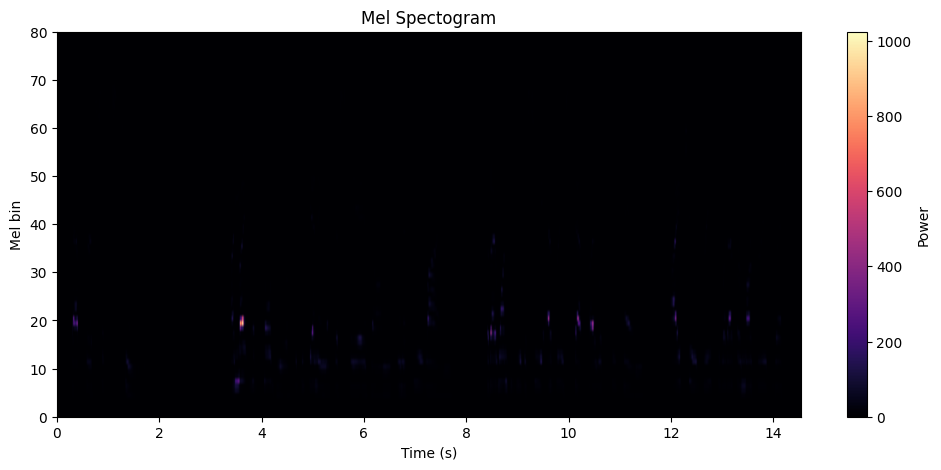

In [8]:
plot_mel_spector(audio_mel_spectr, "Mel Spectogram", "Power", "Time (s)", "Mel bin")

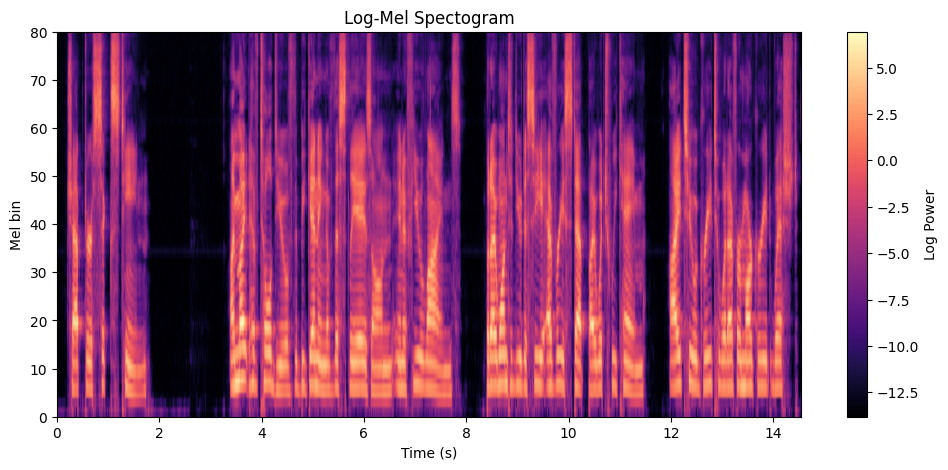

In [9]:
plot_mel_spector(audio_log_mel, "Log-Mel Spectogram", "Log Power", "Time (s)", "Mel bin")